In [16]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from network_SIR import make_network, network_stats, NET_COLORS

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [17]:
n = 374
k = 6
n_instances = 10

rows = []
for kind in ["ER", "WS", "BA"]:
    for i in range(n_instances):
        G = make_network(kind, n, k, seed=i)
        stats = network_stats(G)
        stats["type"] = kind
        rows.append(stats)

df = pd.DataFrame(rows)
df.groupby("type").agg(["mean", "std"]).round(3)

avg degree       max degree         <k^2>/<k>        clustering         \
           mean   std       mean     std      mean    std       mean    std   
type                                                                          
BA        5.952  0.00       59.4  10.024    12.334  0.663      0.063  0.009   
ER        6.099  0.18       15.0   1.944     7.038  0.220      0.017  0.003   
WS        6.000  0.00        8.7   0.483     6.102  0.010      0.440  0.013   

     avg path length        max betweenness        max closeness         
                mean    std            mean    std          mean    std  
type                                                                     
BA             3.119  0.029           0.191  0.043         0.486  0.022  
ER             3.479  0.054           0.032  0.007         0.340  0.008  
WS             5.065  0.117           0.058  0.005         0.238  0.006

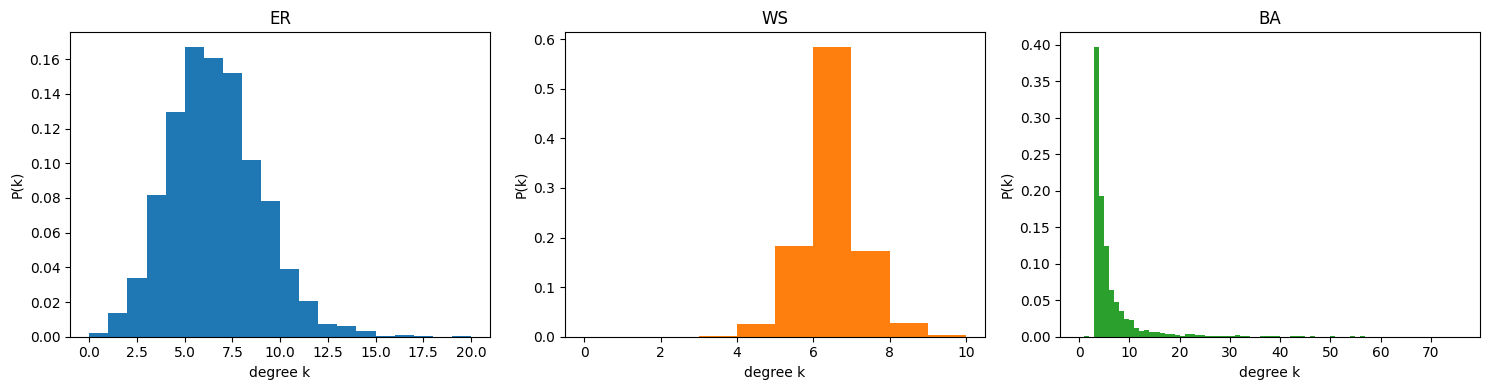

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, kind in zip(axes, ["ER", "WS", "BA"]):
    degrees = []
    for i in range(n_instances):
        G = make_network(kind, n, k, seed=i)
        degrees += [d for node, d in G.degree()]
    ax.hist(degrees, bins=range(0, max(degrees) + 2), density=True, color=NET_COLORS[kind])
    ax.set_title(kind)
    ax.set_xlabel("degree k")
    ax.set_ylabel("P(k)")

plt.tight_layout()
plt.savefig("figures/degree_distributions.png", dpi=200, bbox_inches="tight")
plt.show()

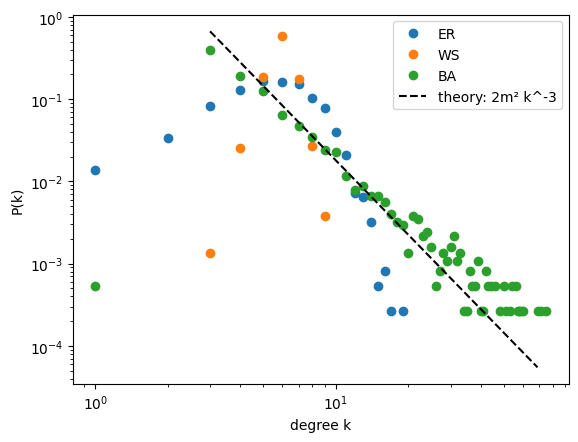

In [19]:
for kind in ["ER", "WS", "BA"]:
    degrees = []
    for i in range(n_instances):
        G = make_network(kind, n, k, seed=i)
        degrees += [d for node, d in G.degree()]
    values, counts = np.unique(degrees, return_counts=True)
    plt.loglog(values, counts / len(degrees), "o", color=NET_COLORS[kind], label=kind)

m = k // 2
k_ref = np.arange(3, 70)
plt.loglog(k_ref, 2 * m**2 * k_ref ** -3.0, "k--", label="theory: 2m² k^-3")

plt.xlabel("degree k")
plt.ylabel("P(k)")
plt.legend()
plt.savefig("figures/degree_distributions_loglog.png", dpi=200, bbox_inches="tight")
plt.show()

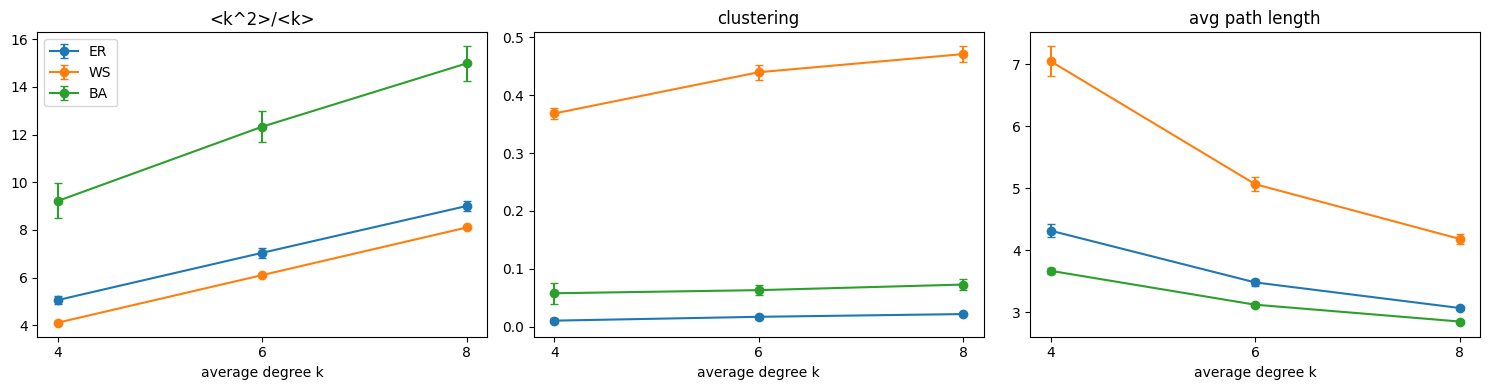

In [20]:
rows = []
for kind in ["ER", "WS", "BA"]:
    for k_test in [4, 6, 8]:
        for i in range(n_instances):
            G = make_network(kind, n, k_test, seed=i)
            stats = network_stats(G)
            stats["type"] = kind
            stats["k"] = k_test
            rows.append(stats)

df_k = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["<k^2>/<k>", "clustering", "avg path length"]):
    for kind in ["ER", "WS", "BA"]:
        sub = df_k[df_k["type"] == kind].groupby("k")[col]
        ax.errorbar(sub.mean().index, sub.mean(), yerr=sub.std(), marker="o", capsize=3,
                    color=NET_COLORS[kind], label=kind)
    ax.set_xlabel("average degree k")
    ax.set_title(col)
    ax.set_xticks([4, 6, 8])
axes[0].legend()
plt.tight_layout()
plt.savefig("figures/network_stats_vs_k.png", dpi=200, bbox_inches="tight")
plt.show()

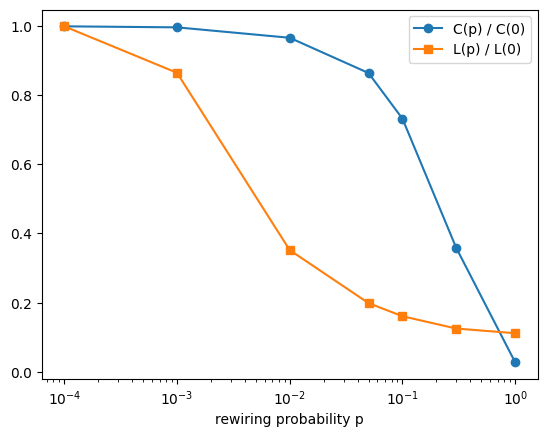

In [21]:
p_values = [0.0, 0.001, 0.01, 0.05, 0.1, 0.3, 1.0]
C = []
L = []

for p in p_values:
    C_runs = []
    L_runs = []
    for i in range(n_instances):
        G = make_network("WS", n, k, seed=i, p_rewire=p)
        C_runs.append(nx.average_clustering(G))
        L_runs.append(nx.average_shortest_path_length(G))
    C.append(np.mean(C_runs))
    L.append(np.mean(L_runs))

x = [max(p, 1e-4) for p in p_values]
plt.semilogx(x, np.array(C) / C[0], "o-", label="C(p) / C(0)")
plt.semilogx(x, np.array(L) / L[0], "s-", label="L(p) / L(0)")
plt.xlabel("rewiring probability p")
plt.legend()
plt.savefig("figures/ws_small_world.png", dpi=200, bbox_inches="tight")
plt.show()